# TP2 - Etapa 2: entrenamiento, evaluación y comparación de modelos

Notebook de entrenamiento y estudio de resultados: evaluación de la búsqueda por similitud
(Etapa 1, NDCG@10), fine-tuning de ResNet (Modelo A), CNN propia (Modelo B) y comparación entre
modelos (ver `ENUNCIADO.md`, secciones 4.3 y 5). **Ambos modelos son obligatorios.**

El entrenamiento se realiza en Colab para aprovechar la GPU:
**Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)**.

Requisitos previos (en tu fork):

- Funciones de la Etapa 1 implementadas en `src/lib/services/similarity_service.py`.
- `train_classifier`, `evaluate_classifier` y `extract_custom_embedding` implementadas en
  `src/lib/services/classifier_service.py` (esta notebook solo las orquesta).
- Splits y conjunto independiente generados en `1-pre-processing.ipynb`.

Al finalizar:

- Descargar los checkpoints generados y colocarlos en `models/` del entorno local
  (la aplicación los usa en las pestañas de las Etapas 1, 2 y 3).
- Publicarlos en un link público de solo lectura para los docentes.
- Entregar esta notebook ejecutada, con sus salidas.


**Notebook en Google Colab (si corresponde):** <reemplazar por el link, con permiso de lectura para los docentes>

Si entregan la notebook en Colab, esta copia del repositorio funciona como notebook de referencia:
el link de arriba es obligatorio y la notebook de Colab debe estar ejecutada, con sus salidas
(ver `ENUNCIADO.md`, sección 8.2).


## Equipo

- Alumno 1 :Norberto Narvaez
- Alumno 2 :


## 1. Clonar el repositorio

Solo si trabajan en Colab. Si tu fork es privado, generá un token de acceso (GitHub → Settings →
Developer settings → Personal access tokens) y usalo en la URL, o subí un zip del proyecto a Colab/Drive.


In [1]:
import sys

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    REPO_URL = "https://github.com/bethoven996/tuia-dog-recognition-app.git"
    BRANCH = "feature/tp2-razas-perros"  # no main: main tiene que quedar igual al repo base
    !git clone -b $BRANCH $REPO_URL proyecto
    %cd proyecto
else:
    print("Entorno local: el repo ya está clonado, no se clona de nuevo.")

Entorno local: el repo ya está clonado, no se clona de nuevo.


## 2. Instalar dependencias

Colab ya incluye torch, torchvision, opencv, numpy, scikit-learn y matplotlib;
solo se instala lo que falta.


In [2]:
#!pip install -q pydantic-settings python-dotenv kagglehub albumentations onnxruntime

## 3. Configuración del entorno

En Colab no hay PostgreSQL, por lo que se desactiva pgvector y se usa la base vectorial JSON.
La configuración se define por variables de entorno **antes** de importar `lib`.


In [3]:
import os
import sys
from pathlib import Path

os.environ["USE_PGVECTOR"] = "false"
# Ajustá acá cualquier otra variable (IMAGE_SIZE, EMBEDDING_DIM, paths, etc.)

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from lib.config import settings

import torch
print("dataset_path:", settings.dataset_path)
print("GPU disponible:", torch.cuda.is_available())

dataset_path: data\dataset
GPU disponible: False


## 4. Dataset y splits

Descargar el dataset y cargar los splits y el conjunto independiente definidos en
`1-pre-processing.ipynb`.


In [4]:
import shutil
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

# Dataset de Kaggle (si ya está descargado, el script no lo vuelve a copiar)
!"{sys.executable}" scripts/download_dataset.py

# Conjunto independiente: en local ya está en data/dataset/independent; en Colab se trae de Drive
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ZIP_IND = Path("/content/drive/MyDrive/tp2/independent.zip")
    if not (settings.dataset_path / "independent").exists():
        shutil.unpack_archive(ZIP_IND, settings.dataset_path)

# Splits definidos en 1-pre-processing.ipynb (rutas relativas a DATASET_PATH)
SPLITS = ["train", "valid", "test", "independent"]
splits = pd.read_csv(settings.data_path / "splits.csv")
splits["abs"] = splits["path"].map(lambda p: settings.dataset_path / p)

faltan = int((~splits["abs"].map(Path.exists)).sum())
print("Imágenes del CSV que no se encuentran en disco:", faltan)
display(splits["split"].value_counts().reindex(SPLITS).rename("imágenes"))

Descargando gpiosenka/70-dog-breedsimage-data-set ...
Ya existe, se omite: C:\Users\Beto\Desktop\FACULTAD\tuia-dog-recognition-app\data\dataset\dogs.csv
Ya existe, se omite: C:\Users\Beto\Desktop\FACULTAD\tuia-dog-recognition-app\data\dataset\test
Ya existe, se omite: C:\Users\Beto\Desktop\FACULTAD\tuia-dog-recognition-app\data\dataset\train
Ya existe, se omite: C:\Users\Beto\Desktop\FACULTAD\tuia-dog-recognition-app\data\dataset\valid
Dataset disponible en C:\Users\Beto\Desktop\FACULTAD\tuia-dog-recognition-app\data\dataset
Imágenes del CSV que no se encuentran en disco: 0


split
train          7652
valid           685
test            696
independent     184
Name: imágenes, dtype: int64

## 5. Etapa 1 — Evaluación de la búsqueda por similitud (baseline)

TO-DO:

- Galería: imágenes de `train`. Consultas: `test` y el conjunto independiente (nunca indexadas).
- Para cada consulta, recuperar las Top-10 y calcular NDCG@10 con relevancia binaria (misma raza).
- Reportar NDCG@10 medio, precision@10 y accuracy de la raza predicha, por separado para `test` y
  para el conjunto independiente.
- Comparar `cosine` vs `l2`, analizar `TOP_K` y calibrar `SIMILARITY_THRESHOLD` con validación.
- Justificar el resultado con ejemplos de consultas y sus Top-10.

Sugerencia: no hace falta la base de datos. Calculá los embeddings de la galería en una matriz de
`numpy` y buscá con un producto matricial (`EmbeddingStore.append` reescribe el JSON en cada llamada).


In [5]:
from lib.bootstrap import build_similarity, build_store
from lib.evaluation.metrics import ndcg_at_k
from lib.schemas import Neighbor

similarity = build_similarity(settings, build_store(settings))

CACHE = settings.output_path / "emb_baseline.npz"
paths = [str(p) for p in splits["abs"]]
if CACHE.exists() and list(np.load(CACHE)["paths"]) == paths:
    E_base = np.load(CACHE)["emb"]
    print("Embeddings leídos de", CACHE)
else:
    E_base = np.array([similarity.extract_embedding(cv2.imread(p)) for p in tqdm(paths)], dtype=np.float32)
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    np.savez(CACHE, emb=E_base, paths=np.array(paths))

print("Matriz de embeddings:", E_base.shape)

c:\Users\Beto\Desktop\FACULTAD\tuia-dog-recognition-app\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
INFO:lib.bootstrap:Using JSON file vector store
  0%|          | 0/9217 [00:00<?, ?it/s]

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\Beto/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:04<00:00, 11.5MB/s]
100%|██████████| 9217/9217 [09:31<00:00, 16.13it/s]


Matriz de embeddings: (9217, 512)


In [7]:
TRAIN = splits["split"].eq("train").to_numpy()
razas_g = splits.loc[TRAIN, "breed"].to_numpy()
n_rel = pd.Series(razas_g).value_counts()  # imágenes de cada raza en la galería (para el NDCG ideal)


def evaluar_busqueda(E, consulta, metrica="cosine", k=10, umbral=0.0):
    """Busca cada consulta en la galería (train) y devuelve una fila de métricas por consulta."""
    G = E[TRAIN]
    q = splits["split"].eq(consulta).to_numpy()
    Q, razas_q = E[q], splits.loc[q, "breed"].to_numpy()

    S = Q @ G.T  # similitud coseno (los vectores están normalizados)
    if metrica == "l2":
        S = 1 / (1 + np.sqrt(np.clip(2 - 2 * S, 0, None)))  # misma fórmula que el servicio: 1 / (1 + distancia)
    top = np.argsort(-S, axis=1)[:, :k]

    similarity.similarity_threshold = umbral
    filas = []
    for i in range(len(Q)):
        rel = (razas_g[top[i]] == razas_q[i]).astype(float)
        vecinos = [Neighbor(path=str(j), breed=razas_g[j], score=float(S[i, j])) for j in top[i]]
        pred, _ = similarity.predict_breed_from_neighbors(vecinos)  # la misma función que usa la app
        filas.append({
            "raza": razas_q[i],
            "ndcg": ndcg_at_k(rel, k=k, n_relevant=int(n_rel[razas_q[i]])),
            "precision": rel.mean(),
            "pred": pred,
            "acierto": pred == razas_q[i],
            "mejor_score": float(S[i, top[i][0]]),
            "top": top[i],
        })
    return pd.DataFrame(filas)


resultados = {}
tabla = []
for metrica in ["cosine", "l2"]:
    for consulta in ["test", "independent"]:
        r = evaluar_busqueda(E_base, consulta, metrica)
        resultados[(metrica, consulta)] = r
        tabla.append({"métrica": metrica, "consultas": consulta, "n": len(r),
                      "NDCG@10": r["ndcg"].mean(), "Precision@10": r["precision"].mean(),
                      "Accuracy raza": r["acierto"].mean()})
display(pd.DataFrame(tabla).round(3))

,métrica,consultas,n,NDCG@10,Precision@10,Accuracy raza
0,cosine,test,696,0.873,0.860,0.932
1,cosine,independent,184,0.474,0.467,0.565
2,l2,test,696,0.873,0.860,0.932
3,l2,independent,184,0.474,0.467,0.565


**Resultados del baseline (ResNet18 preentrenada en ImageNet, sin entrenamiento)**

En test, la búsqueda alcanza NDCG@10 = 0,873, Precision@10 = 0,860 y una accuracy de raza de 0,932 por
voto ponderado, sin entrenar ningún modelo: los embeddings genéricos de ImageNet ya separan bien las razas
del dataset. `cosine` y `l2` dan resultados idénticos en todas las métricas: con embeddings normalizados L2
ambas métricas ordenan los vecinos de la misma forma (distancia² = 2 − 2·coseno), y solo cambia la escala
del score.

En el conjunto independiente el rendimiento cae a NDCG@10 = 0,474 y accuracy = 0,565. La caída refleja el
cambio de dominio: en el dataset el perro ocupa el 80–100 % de la imagen (6.4 de la notebook 1), mientras
que las fotos de Wikimedia tienen el perro más chico, más fondo y proporciones no cuadradas. Además, el
conjunto independiente se construyó con razas fáciles de confundir, por lo que es más difícil que el
promedio de test.


Accuracy        NDCG@k       
consultas     test  valid   test  valid
TOP_K                                  
1            0.925  0.902  0.925  0.902
3            0.934  0.924  0.904  0.893
5            0.940  0.928  0.893  0.882
10           0.932  0.937  0.873  0.864
20           0.930  0.923  0.844  0.839

Umbral elegido (p2 de valid): 0.836
Perros de valid rechazados como 'unknown': 2.0%
Imágenes sin perros rechazadas como 'unknown': 95.2% (21 imágenes)


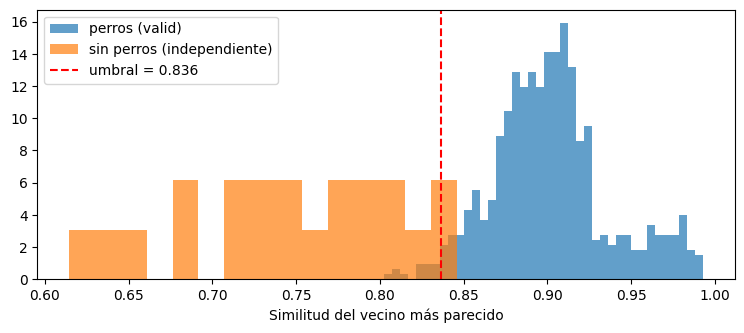

In [8]:
# 1) Efecto de TOP_K: se elige con valid, se reporta también test
filas = []
for k in [1, 3, 5, 10, 20]:
    for consulta in ["valid", "test"]:
        r = evaluar_busqueda(E_base, consulta, "cosine", k=k)
        filas.append({"TOP_K": k, "consultas": consulta, "Accuracy": r["acierto"].mean(), "NDCG@k": r["ndcg"].mean()})
display(pd.DataFrame(filas).pivot(index="TOP_K", columns="consultas", values=["Accuracy", "NDCG@k"]).round(3))

# 2) Umbral: percentil 2 del mejor score de los perros de valid (regla fijada antes de mirar resultados)
r_valid = evaluar_busqueda(E_base, "valid", "cosine")
UMBRAL = float(np.quantile(r_valid["mejor_score"], 0.02))
print(f"Umbral elegido (p2 de valid): {UMBRAL:.3f}")

# Solo para reportar: ¿cuántas imágenes sin perros quedan por debajo del umbral?
IND = settings.dataset_path / "independent"
fuentes = pd.read_csv(IND / "fuentes.csv")
sin_perros = fuentes[fuentes["tipo"] == "sin_perro"]
E_sin = np.array([similarity.extract_embedding(cv2.imread(str(IND / a))) for a in sin_perros["archivo"]], dtype=np.float32)
mejor_sin = (E_sin @ E_base[TRAIN].T).max(axis=1)
print(f"Perros de valid rechazados como 'unknown': {(r_valid['mejor_score'] < UMBRAL).mean():.1%}")
print(f"Imágenes sin perros rechazadas como 'unknown': {(mejor_sin < UMBRAL).mean():.1%} ({len(mejor_sin)} imágenes)")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(r_valid["mejor_score"], bins=40, alpha=0.7, label="perros (valid)", density=True)
ax.hist(mejor_sin, bins=15, alpha=0.7, label="sin perros (independiente)", density=True)
ax.axvline(UMBRAL, color="red", ls="--", label=f"umbral = {UMBRAL:.3f}")
ax.set_xlabel("Similitud del vecino más parecido")
ax.legend()
plt.show()

**`TOP_K` y umbral de similitud**

- **TOP_K = 10**, elegido con valid (accuracy 0,937, la más alta en ese split). Con pocos vecinos la
  predicción depende demasiado del primero (k = 1: 0,902 en valid) y con muchos entran vecinos de otras
  razas a la votación (k = 20: 0,923). En test, k = 5 da un valor apenas mayor (0,940 contra 0,932), pero
  la elección se hace con valid para no ajustar con el conjunto de evaluación. El NDCG@k disminuye al
  aumentar k porque es más difícil que todas las posiciones de un ranking largo sean de la raza correcta.
- **SIMILARITY_THRESHOLD = 0,836** (métrica coseno). Valid solo contiene perros de las 70 razas, por lo
  que optimizar el umbral únicamente con ese split llevaría siempre al valor más bajo. Se fijó de antemano
  una regla: el umbral es el percentil 2 de la similitud del vecino más parecido en valid, es decir, se
  acepta rechazar como `unknown` al 2 % de los perros reales. Con ese umbral se rechaza el 95,2 % de las
  imágenes sin perros del conjunto independiente (20 de 21), que se usaron solo para reportar, no para
  elegir. Las distribuciones de ambos grupos se superponen apenas entre 0,80 y 0,85. El umbral corresponde
  a la métrica coseno: con L2 el score tiene otra escala y habría que recalibrarlo.


Las 10 razas con peor NDCG@10 en test:


,NDCG test,Acc test,NDCG indep,Acc indep
raza,,,,
Bulldog,0.33,0.30,NaN,NaN
Malinois,0.55,0.80,0.64,0.88
Labradoodle,0.63,0.70,0.20,0.22
Cockapoo,0.63,0.78,0.19,0.10
Boston Terrier,0.65,0.80,0.42,0.50
Rhodesian,0.66,0.70,0.67,1.00
Bull Mastiff,0.67,0.70,NaN,NaN
Bull Terrier,0.68,0.70,NaN,NaN
American Hairless,0.69,0.70,NaN,NaN



Confusiones más frecuentes en test (real -> predicha):


raza               pred          
Bulldog            Boston Terrier    4
Bull Mastiff       Boxer             3
American Hairless  Mex Hairless      3
Labradoodle        Cockapoo          3
Boston Terrier     Bulldog           2
Bull Terrier       Basenji           2
American Spaniel   Irish Spaniel     2
German Sheperd     Malinois          2
Cockapoo           Labradoodle       2
Rhodesian          Vizsla            2
Name: veces, dtype: int64

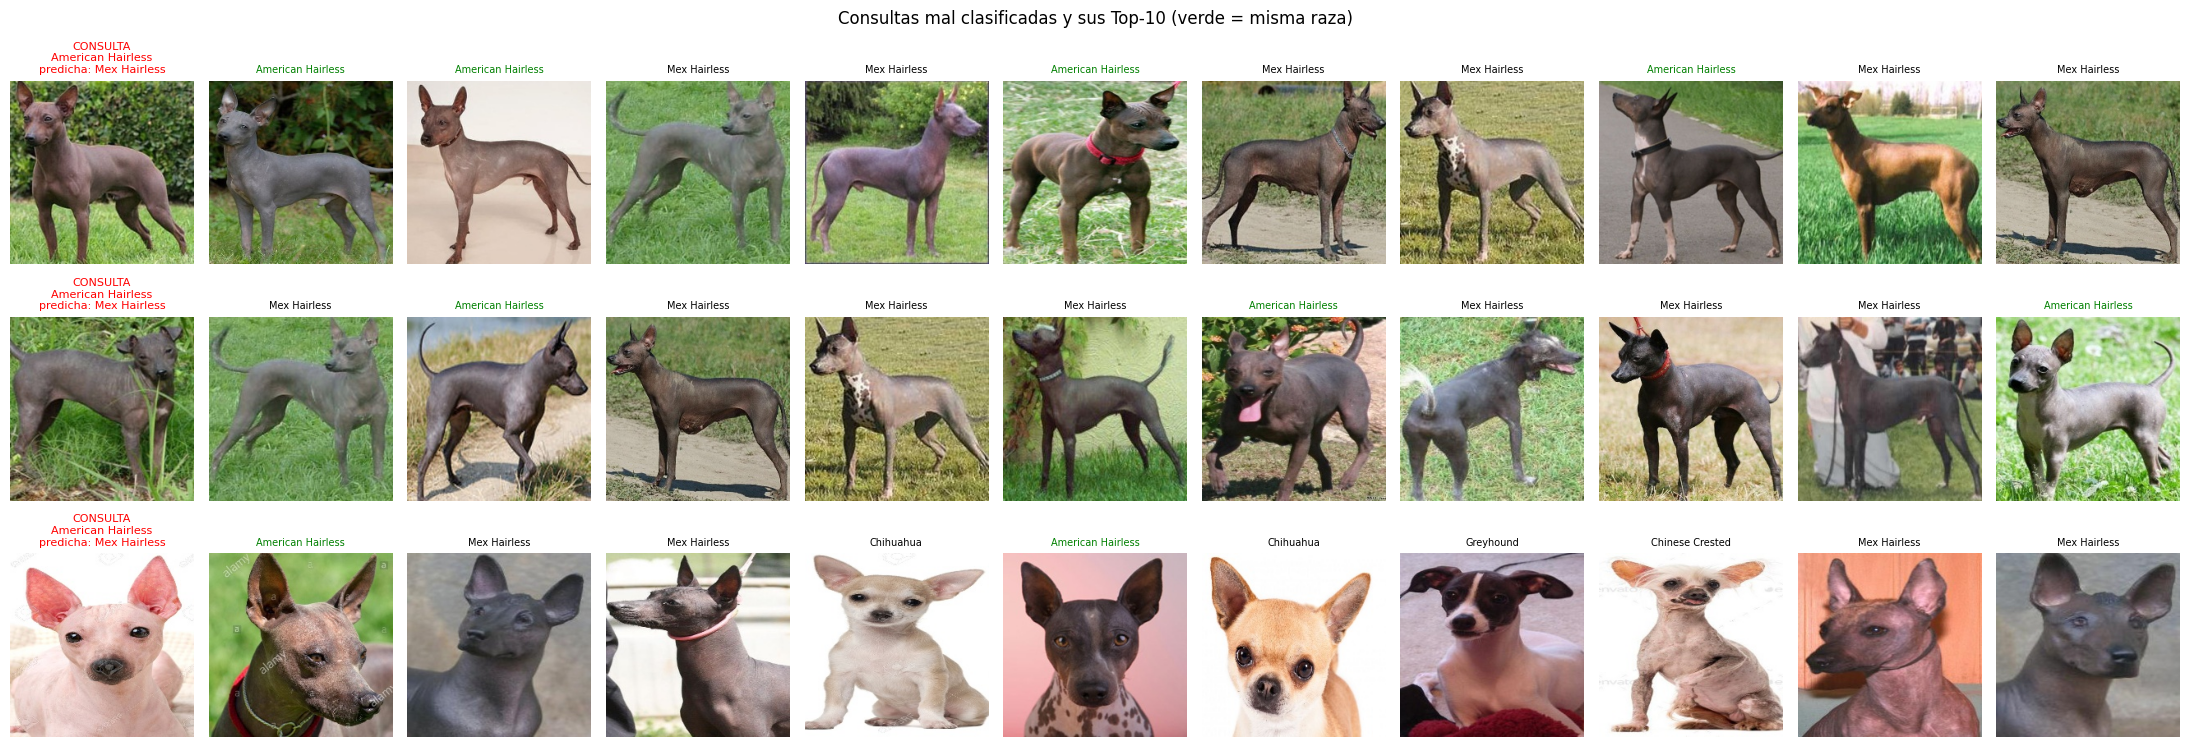

In [9]:
r_test = resultados[("cosine", "test")]
r_ind = resultados[("cosine", "independent")]

# 1) Razas con peor NDCG@10 en test y en el conjunto independiente
por_raza = pd.DataFrame({
    "NDCG test": r_test.groupby("raza")["ndcg"].mean(),
    "Acc test": r_test.groupby("raza")["acierto"].mean(),
    "NDCG indep": r_ind.groupby("raza")["ndcg"].mean(),
    "Acc indep": r_ind.groupby("raza")["acierto"].mean(),
})
print("Las 10 razas con peor NDCG@10 en test:")
display(por_raza.sort_values("NDCG test").head(10).round(2))

# 2) Con qué raza se confunden los errores
errores = r_test[~r_test["acierto"]]
print("\nConfusiones más frecuentes en test (real -> predicha):")
display(errores.groupby(["raza", "pred"]).size().sort_values(ascending=False).head(10).rename("veces"))

# 3) Ejemplos visuales: consultas mal clasificadas y sus Top-10
paths_g = splits.loc[TRAIN, "abs"].to_numpy()
paths_test = splits.loc[splits["split"].eq("test"), "abs"].to_numpy()
ejemplos = errores.head(3)
fig, axes = plt.subplots(len(ejemplos), 11, figsize=(22, 2.6 * len(ejemplos)), squeeze=False)
for fila_ax, (i, fila) in zip(axes, ejemplos.iterrows()):
    fila_ax[0].imshow(cv2.imread(str(paths_test[i]))[:, :, ::-1])
    fila_ax[0].set_title(f"CONSULTA\n{fila['raza']}\npredicha: {fila['pred']}", fontsize=8, color="red")
    for ax, j in zip(fila_ax[1:], fila["top"]):
        ax.imshow(cv2.imread(str(paths_g[j]))[:, :, ::-1])
        ax.set_title(razas_g[j], fontsize=7, color="green" if razas_g[j] == fila["raza"] else "black")
    for ax in fila_ax:
        ax.axis("off")
plt.suptitle("Consultas mal clasificadas y sus Top-10 (verde = misma raza)")
plt.tight_layout()
plt.show()

**Análisis de errores**

Las confusiones más frecuentes en test coinciden con los pares de razas parecidas identificados en el EDA
(sección 6.3 de la notebook 1): Labradoodle ↔ Cockapoo, American Hairless → Mex Hairless, German Sheperd →
Malinois, Rhodesian → Vizsla y Bulldog ↔ Boston Terrier. American Spaniel → Irish Spaniel es además uno de
los pares con etiquetas en conflicto detectados por la regla 6, lo que indica que la confusión afecta
también al etiquetado del dataset.

La raza con peor resultado es Bulldog (NDCG@10 = 0,33, accuracy = 0,30), confundida con Boston Terrier.
En la inspección visual del EDA ya se había encontrado una imagen etiquetada como "Bulldog" que parece un
Boston Terrier: si hay varias en la galería, las búsquedas de ambas razas se mezclan. Es una hipótesis de
ruido en las etiquetas.

En el conjunto independiente fallan sobre todo las cruzas (Labradoodle: accuracy 0,22; Cockapoo: 0,10),
que no tienen un estándar de raza fijo y varían mucho entre ejemplares, mientras que razas con rasgos
distintivos como Rhodesian (1,00) o Malinois (0,88) se reconocen bien con fotos nuevas.

Los ejemplos visuales muestran el mecanismo del error: American Hairless y Mex Hairless son prácticamente
indistinguibles y las vecinas se reparten entre ambas razas; en el primer caso las dos vecinas más
parecidas son de la raza correcta, pero el voto lo gana la otra raza por tener más vecinas en el Top-10.
En el tercero, un primer plano, la forma de las orejas atrae vecinas de Chihuahua.


## 6. Modelo A (obligatorio): fine-tuning de ResNet

`train_classifier` debe guardar el checkpoint en `models/resnet18_finetuned.pth`
(o el nombre configurado en `RESNET18_MODEL_NAME`). Documentar la estrategia de fine-tuning
y los hiperparámetros utilizados (learning rate, batch size, epochs, optimizador, scheduler,
regularización).


In [ ]:
import json
from lib.bootstrap import build_classifier

classifier = build_classifier(settings)
classifier.set_active_model("resnet18_finetuned")
HIST_A = settings.output_path / "history_resnet18_finetuned.json"
historiales_a = {}

# Estrategia 1: feature extraction (backbone congelado, solo se entrena la capa nueva)
classifier.hparams = {"strategy": "feature_extraction", "epochs": 8}
classifier.train_classifier()
historiales_a["feature_extraction"] = json.loads(HIST_A.read_text())
valid_fe = classifier.evaluate_classifier(split="valid")

# Estrategia 2: fine-tuning completo con learning rates diferenciados (queda como checkpoint final)
classifier.hparams = {"strategy": "fine_tuning"}
classifier.train_classifier()
historiales_a["fine_tuning"] = json.loads(HIST_A.read_text())
valid_ft = classifier.evaluate_classifier(split="valid")

print("Hiperparámetros del modelo final:")
display(pd.Series(historiales_a["fine_tuning"]["hparams"]))
print("Comparación de estrategias en valid:")
display(pd.DataFrame({"feature extraction": valid_fe, "fine-tuning": valid_ft}).round(3))

NotImplementedError: Etapa 2: implementar train_classifier

In [ ]:
metrics_a = classifier.evaluate_classifier()
metrics_a

### Curvas de entrenamiento y matriz de confusión (Modelo A)

TO-DO: graficar las curvas de entrenamiento/validación (loss y accuracy) y la matriz de confusión
normalizada, con los pares de razas más confundidos.


In [ ]:
## TO-DO: curvas de entrenamiento y matriz de confusión del Modelo A.

## 7. Modelo B (obligatorio): CNN propia

`train_classifier` con el modelo activo `cnn_custom` debe guardar el checkpoint en
`models/cnn_custom.pth` (o el nombre configurado en `CNN_CUSTOM_MODEL_NAME`).
Definí la arquitectura en un módulo importable (por ejemplo, `src/lib/models/cnn_custom.py`):
si la clase vive en la notebook, `torch.load` falla en la app.

TO-DO: documentar la arquitectura (capas, parámetros, dimensión del embedding), los
hiperparámetros y la tabla de experimentos.


In [ ]:
classifier.set_active_model("cnn_custom")
classifier.train_classifier()

In [ ]:
metrics_b = classifier.evaluate_classifier()
metrics_b

### Curvas de entrenamiento y matriz de confusión (Modelo B)


In [ ]:
## TO-DO: curvas de entrenamiento y matriz de confusión del Modelo B.

## 8. Evaluación sobre el conjunto independiente

TO-DO: las mismas métricas sobre el conjunto independiente para ambos modelos. Comparar con `test`
y discutir el cambio de dominio.


In [ ]:
## TO-DO: métricas de ambos modelos sobre el conjunto independiente.

## 9. Embeddings de los modelos entrenados

TO-DO:

- NDCG@10 de la Etapa 1 con los embeddings del baseline, del Modelo A y del Modelo B
  (`classifier.extract_custom_embedding`), con la misma galería y las mismas consultas.
- Visualización PCA o t-SNE de los embeddings de `test` de cada modelo, lado a lado y coloreada
  por raza (con un subconjunto de razas).


In [ ]:
## TO-DO: NDCG@10 por modelo de embeddings y visualización PCA / t-SNE.

## 10. Análisis de errores

TO-DO: ejemplos de falsos positivos y falsos negativos con la imagen y su score, razas con peor
desempeño e hipótesis sobre las causas.


In [ ]:
## TO-DO: análisis de errores con ejemplos visuales.

## 11. Costo computacional

TO-DO: cantidad de parámetros, tamaño en MB, tiempo de inferencia por imagen en CPU y dimensión
del embedding de cada modelo.


In [ ]:
## TO-DO: costo computacional de cada modelo.

## 12. Comparación y elección final

TO-DO:

- Tabla comparativa de todas las métricas (Modelo A, Modelo B y baseline en la Etapa 1).
- Qué modelo usa la app para clasificar (Etapas 2 y 3) y qué embeddings para la búsqueda
  (`EMBEDDING_MODEL`), con su justificación.
- Búsqueda por similitud vs. clasificación supervisada: ventajas, limitaciones y cuándo conviene cada una.
- Trade-offs entre precisión, velocidad de inferencia, memoria y complejidad.


In [ ]:
## TO-DO: tabla comparativa final.

## 13. Descargar los checkpoints

Descargalos y colocalos en `models/` de tu entorno local para que la aplicación los use.
Recordá publicarlos en un link público de solo lectura y ponerlo en el README y en el PR.


In [ ]:
!ls -lh models/

try:
    from google.colab import files

    files.download(str(settings.model_path / settings.resnet18_model_name))
    files.download(str(settings.model_path / settings.cnn_custom_model_name))
except ImportError:
    print("Fuera de Colab: los checkpoints quedan en models/")